<h2 style="color:rgb(0,120,170)">Scenario 2: Only path search</h2>

**Question:** if the map doesn't change, how fast is a single query once the graph is already built?

**Setup:** graph does not rebuild, start and goal are fixed, for each batch, the first map is used. The graph is built once, before the timer starts, and then only the search is timed.

The maps are the 7 batches from `maps/maps.ipynb` (10 maps each, 10 × 10, start (0, 0), goal (10, 10)), loaded from `maps/maps_batches.json`. Run `maps/maps.ipynb` first if the file doesn't exist.

| column | batch |
|---|---|
| batch_1 | different amount of obstacles (2–7, convex) |
| batch_2 | convex/concave obstacles |
| batch_3 | no obstacles |
| batch_4 | obstacles make no impact (straight line free) |
| batch_5 | few obstacles (2) |
| batch_6 | many obstacles (7) |
| batch_7 | random placement |

In [1]:
from utils.compare_tables_util import show_benchmark_tables
from utils.path_planning_utils import benchmark_first_map_fixed_points_reuse
from utils.plot_utils import plot_algorithm_batch_means

In [2]:
from utils.maps_generation_utils import END, START, load_batches

obstacle_batches = load_batches("maps/maps_batches.json")
start, end = START, END
print(len(obstacle_batches), "batches,", [len(b) for b in obstacle_batches], "maps")

7 batches, [10, 10, 10, 10, 10, 10, 10] maps


### Settings

In [3]:
TRIALS = 10
RRT_KWARGS = {"iterations": 2000}
PRM_KWARGS = {"n_samples": 250, "k": 8}

### Run the benchmark

In [4]:
scenario2_tables = benchmark_first_map_fixed_points_reuse(
    obstacle_batches,
    start,
    end,
    trials=TRIALS,
    rrt_kwargs=RRT_KWARGS,
    prm_kwargs=PRM_KWARGS,
)

### Results per trial
Runtime in seconds. Rows are trials, columns are batches (first map of each batch).

In [5]:
show_benchmark_tables("Scenario 2", scenario2_tables)

### Scenario 2: VG

| map | batch_1 | batch_2 | batch_3 | batch_4 | batch_5 | batch_6 | batch_7 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| trial_1 | 0.001341 | 0.002357 | 0.000017 | 0.000456 | 0.000295 | 0.001310 | 0.001301 |
| trial_2 | 0.001337 | 0.002599 | 0.000017 | 0.000486 | 0.000282 | 0.001358 | 0.001251 |
| trial_3 | 0.001304 | 0.002344 | 0.000017 | 0.000447 | 0.000278 | 0.001363 | 0.001407 |
| trial_4 | 0.001332 | 0.002311 | 0.000017 | 0.000472 | 0.000268 | 0.001331 | 0.001325 |
| trial_5 | 0.001494 | 0.002289 | 0.000017 | 0.000473 | 0.000262 | 0.001304 | 0.001426 |
| trial_6 | 0.001297 | 0.002293 | 0.000019 | 0.000477 | 0.000287 | 0.001297 | 0.001242 |
| trial_7 | 0.001354 | 0.002226 | 0.000017 | 0.000470 | 0.000285 | 0.001351 | 0.001254 |
| trial_8 | 0.001338 | 0.002272 | 0.000018 | 0.000482 | 0.000258 | 0.001338 | 0.001269 |
| trial_9 | 0.001371 | 0.002290 | 0.000018 | 0.000449 | 0.000260 | 0.001297 | 0.001279 |
| trial_10 | 0.001307 | 0.002270 | 0.000017 | 0.000446 | 0.000269 | 0.001336 | 0.001266 |

### Scenario 2: VG summary

| batch | success_rate | median | mean | min | max | valid |
| --- | --- | --- | --- | --- | --- | --- |
| batch_1 | 100.0% | 0.001337 | 0.001347 | 0.001297 | 0.001494 | 10/10 |
| batch_2 | 100.0% | 0.002291 | 0.002325 | 0.002226 | 0.002599 | 10/10 |
| batch_3 | 100.0% | 0.000017 | 0.000018 | 0.000017 | 0.000019 | 10/10 |
| batch_4 | 100.0% | 0.000471 | 0.000466 | 0.000446 | 0.000486 | 10/10 |
| batch_5 | 100.0% | 0.000274 | 0.000274 | 0.000258 | 0.000295 | 10/10 |
| batch_6 | 100.0% | 0.001333 | 0.001328 | 0.001297 | 0.001363 | 10/10 |
| batch_7 | 100.0% | 0.001274 | 0.001302 | 0.001242 | 0.001426 | 10/10 |

Overall:
- success_rate: 100.0%
- median: 0.001274
- mean: 0.001009
- min: 0.000017
- max: 0.002599
- valid: 70/70

### Scenario 2: RRT_star

| map | batch_1 | batch_2 | batch_3 | batch_4 | batch_5 | batch_6 | batch_7 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| trial_1 | 0.010298 | 0.009041 | 0.005916 | 0.007690 | 0.011553 | 0.016487 | 0.010052 |
| trial_2 | 0.011119 | 0.010179 | 0.005174 | 0.006425 | 0.008824 | 0.023094 | 0.011103 |
| trial_3 | 0.011556 | 0.009041 | 0.006053 | 0.006681 | 0.008222 | 0.016564 | 0.010870 |
| trial_4 | 0.012448 | 0.010151 | 0.005600 | 0.006065 | 0.008939 | 0.019196 | 0.013928 |
| trial_5 | 0.013746 | 0.011255 | 0.006829 | 0.006547 | 0.009427 | 0.015490 | 0.008987 |
| trial_6 | 0.014608 | 0.009168 | 0.005451 | 0.006708 | 0.008791 | 0.021110 | 0.009555 |
| trial_7 | 0.013855 | 0.010965 | 0.005502 | 0.006756 | 0.008067 | 0.016227 | 0.009355 |
| trial_8 | 0.012951 | 0.009420 | 0.006037 | 0.005545 | 0.008297 | 0.014673 | 0.010228 |
| trial_9 | 0.011847 | 0.009074 | 0.006743 | 0.007163 | 0.008082 | 0.015768 | 0.009882 |
| trial_10 | 0.014664 | 0.008826 | 0.006631 | 0.006080 | 0.013218 | 0.017096 | 0.009459 |

### Scenario 2: RRT_star summary

| batch | success_rate | median | mean | min | max | valid |
| --- | --- | --- | --- | --- | --- | --- |
| batch_1 | 100.0% | 0.012700 | 0.012709 | 0.010298 | 0.014664 | 10/10 |
| batch_2 | 100.0% | 0.009294 | 0.009712 | 0.008826 | 0.011255 | 10/10 |
| batch_3 | 100.0% | 0.005976 | 0.005993 | 0.005174 | 0.006829 | 10/10 |
| batch_4 | 100.0% | 0.006614 | 0.006566 | 0.005545 | 0.007690 | 10/10 |
| batch_5 | 100.0% | 0.008807 | 0.009342 | 0.008067 | 0.013218 | 10/10 |
| batch_6 | 100.0% | 0.016525 | 0.017570 | 0.014673 | 0.023094 | 10/10 |
| batch_7 | 100.0% | 0.009967 | 0.010342 | 0.008987 | 0.013928 | 10/10 |

Overall:
- success_rate: 100.0%
- median: 0.009424
- mean: 0.010319
- min: 0.005174
- max: 0.023094
- valid: 70/70

### Scenario 2: PRM

| map | batch_1 | batch_2 | batch_3 | batch_4 | batch_5 | batch_6 | batch_7 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| trial_1 | 0.001100 | 0.000824 | 0.000647 | 0.000779 | 0.000756 | 0.000858 | 0.000899 |
| trial_2 | 0.000950 | 0.000910 | 0.000650 | 0.000759 | 0.000702 | 0.000935 | 0.000917 |
| trial_3 | 0.000940 | 0.000878 | 0.000623 | 0.000740 | 0.000775 | 0.000948 | 0.000955 |
| trial_4 | 0.000971 | 0.000896 | 0.000616 | 0.000688 | 0.000785 | 0.001028 | 0.000918 |
| trial_5 | 0.000998 | 0.000965 | 0.000666 | 0.000779 | 0.000760 | 0.001011 | 0.000875 |
| trial_6 | 0.000957 | 0.000902 | 0.000673 | 0.000743 | 0.000781 | 0.000971 | 0.000858 |
| trial_7 | 0.000956 | 0.000880 | 0.000635 | 0.000687 | 0.000755 | 0.000918 | 0.000892 |
| trial_8 | 0.000946 | 0.000889 | 0.000645 | 0.000697 | 0.000799 | 0.000907 | 0.000890 |
| trial_9 | 0.000924 | 0.000887 | 0.000647 | 0.000747 | 0.000731 | 0.000967 | 0.000898 |
| trial_10 | 0.000979 | 0.000883 | 0.000616 | 0.000742 | 0.000767 | 0.000841 | 0.000946 |

### Scenario 2: PRM summary

| batch | success_rate | median | mean | min | max | valid |
| --- | --- | --- | --- | --- | --- | --- |
| batch_1 | 100.0% | 0.000956 | 0.000972 | 0.000924 | 0.001100 | 10/10 |
| batch_2 | 100.0% | 0.000888 | 0.000892 | 0.000824 | 0.000965 | 10/10 |
| batch_3 | 100.0% | 0.000646 | 0.000642 | 0.000616 | 0.000673 | 10/10 |
| batch_4 | 100.0% | 0.000743 | 0.000736 | 0.000687 | 0.000779 | 10/10 |
| batch_5 | 100.0% | 0.000764 | 0.000761 | 0.000702 | 0.000799 | 10/10 |
| batch_6 | 100.0% | 0.000942 | 0.000938 | 0.000841 | 0.001028 | 10/10 |
| batch_7 | 100.0% | 0.000899 | 0.000905 | 0.000858 | 0.000955 | 10/10 |

Overall:
- success_rate: 100.0%
- median: 0.000876
- mean: 0.000835
- min: 0.000616
- max: 0.001100
- valid: 70/70

### Mean search time per batch
How to read it: once the graph exists, VG and PRM only run Dijkstra on a small graph, so they should be orders of magnitude faster than in Scenario 1. RRT\* stays at its full runtime. A log scale may be needed to see VG and PRM next to RRT\*.

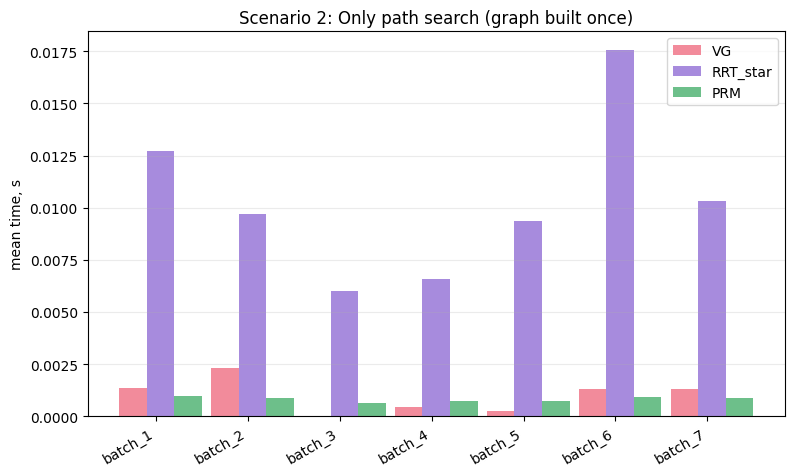

In [6]:
plot_algorithm_batch_means(
    scenario2_tables,
    title="Scenario 2: Only path search (graph built once)",
    ylabel="mean time, s",
);

**Result:** We observe that **PRM** and **VG** clearly outperform, as they no longer spend time on repeated graph construction. In contrast, **RRT\*** rebuilds and extends its tree at every iteration.